In [24]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from scipy.signal import periodogram
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from statsmodels.tsa.seasonal import STL
from statsmodels.nonparametric.smoothers_lowess import lowess
import re
import torch
import torch.nn as nn
import os
import pickle
import warnings
warnings.filterwarnings("ignore")

In [13]:
# ======================================================================
#  Shared building blocks
#  feature extraction -> clustering -> log -> STL -> windows + local norm
# ======================================================================

FEATURE_NAMES = ["mean", "var", "acf1", "trend", "linearity", "curvature", "season",
                 "peak", "trough", "entropy", "lumpiness", "spikiness", "lshift",
                 "vchange", "fspots", "cpoints", "klscore", "change_idx"]

In [14]:
# ----------------------------------------------------------------------
# STL (deterministic seasonality == R's s.window = "periodic")
# ----------------------------------------------------------------------
def stl_periodic(x, freq):
    n = len(x)
    # R: s.window="periodic" -> s.window = 10*n+1, s.degree = 0
    res = STL(x, period=freq, seasonal=10 * n + 1, seasonal_deg=0, robust=False).fit()
    return np.asarray(res.trend), np.asarray(res.seasonal), np.asarray(res.resid)


def decompose(w, freq):
    """trend, seasonal, remainder. Series with < 2 full periods are treated as
    non-seasonal (paper, Sec. 3.6): no deseasonalisation, trend := series itself."""
    w = np.asarray(w, float)
    if freq > 1 and len(w) >= 2 * freq:
        return stl_periodic(w, freq)
    return w.copy(), np.zeros_like(w), np.zeros_like(w)

In [15]:
# ----------------------------------------------------------------------
# 18 interpretable features
# Python re-implementation of R's anomalous-acm::tsmeasures (approximation).
# ----------------------------------------------------------------------
def _ortho_poly_coefs(y, degree=2):
    t = np.linspace(-1, 1, len(y))
    V = np.vander(t, degree + 1, increasing=True)
    Q, R = np.linalg.qr(V)
    Q = Q * np.sign(np.diag(R))          # make column signs deterministic
    return Q.T @ y                        # coefs for [const, linear, quadratic]


def _runs(a):
    if len(a) == 0:
        return 0
    ch = np.flatnonzero(np.diff(a) != 0)
    edges = np.r_[-1, ch, len(a) - 1]
    return int(np.max(np.diff(edges)))


def tsmeasures(y, freq):
    y = np.asarray(y, float)
    n = len(y)
    width = freq if freq > 1 else 10
    sd = y.std()
    ys = (y - y.mean()) / (sd if sd > 1e-12 else 1.0)       # scalets()
    f = dict.fromkeys(FEATURE_NAMES, 0.0)
    f["mean"], f["var"] = float(y.mean()), float(y.var())
    f["acf1"] = float(np.corrcoef(ys[:-1], ys[1:])[0, 1]) if n > 2 and ys.std() > 0 else 0.0

    if freq > 1 and n >= 2 * freq:
        trend, seas, rem = stl_periodic(ys, freq)
    else:
        trend = lowess(ys, np.arange(n), frac=0.5, return_sorted=False)
        seas, rem = np.zeros(n), ys - trend
    vr = np.var(rem)
    vt, vs = np.var(trend + rem), np.var(seas + rem)
    f["trend"] = max(0.0, 1 - vr / vt) if vt > 1e-12 else 0.0
    f["season"] = max(0.0, 1 - vr / vs) if (vs > 1e-12 and np.any(seas)) else 0.0
    co = _ortho_poly_coefs(trend, 2)
    f["linearity"], f["curvature"] = float(co[1]), float(co[2])
    if np.any(seas):
        f["peak"], f["trough"] = float(seas[:freq].max()), float(seas[:freq].min())

    _, psd = periodogram(ys)
    psd = psd[psd > 0]
    p = psd / psd.sum() if psd.size else np.array([1.0])
    f["entropy"] = float(-(p * np.log(p)).sum() / np.log(len(p))) if len(p) > 1 else 0.0

    tiles = [ys[i:i + width].var() for i in range(0, n - width + 1, width)]
    f["lumpiness"] = float(np.var(tiles)) if len(tiles) > 1 else 0.0
    s1, s2 = rem.sum(), (rem ** 2).sum()
    loo = (s2 - rem ** 2) / (n - 1) - ((s1 - rem) / (n - 1)) ** 2
    f["spikiness"] = float(np.var(loo))

    if n >= 2 * width:
        win = np.lib.stride_tricks.sliding_window_view(ys, width)
        m, v = win.mean(1), win.var(1)
        f["lshift"] = float(np.max(np.abs(m[width:] - m[:-width])))
        f["vchange"] = float(np.max(np.abs(v[width:] - v[:-width])))
        # KL score between adjacent windows (Gaussian approximation)
        best, idx = 0.0, 0
        for t in range(width, n - width + 1):
            a, b = ys[t - width:t], ys[t:t + width]
            sa, sb = max(a.std(), 1e-3), max(b.std(), 1e-3)
            kl = np.log(sb / sa) + (sa ** 2 + (a.mean() - b.mean()) ** 2) / (2 * sb ** 2) - 0.5
            if kl > best:
                best, idx = kl, t
        f["klscore"], f["change_idx"] = float(best), idx / n

    bins = np.minimum(((ys - ys.min()) / (np.ptp(ys) + 1e-12) * 10).astype(int), 9)
    f["fspots"] = float(_runs(bins))
    f["cpoints"] = float(np.sum(np.diff(np.sign(ys - np.median(ys))) != 0))
    return np.array([f[k] for k in FEATURE_NAMES])


def extract_features(series_list, freq):
    F = np.stack([tsmeasures(s, freq) for s in series_list])
    return (F - F.mean(0)) / (F.std(0) + 1e-8)   # z-score across series

In [16]:
# ----------------------------------------------------------------------
# Clustering: kmeans (elbow | silhouette), PAM (silhouette), DBSCAN, Snob (MML)
# ----------------------------------------------------------------------
def _relabel(l):
    return np.unique(l, return_inverse=True)[1]


def _pam(D, k):
    n = len(D)
    med = [int(np.argmin(D.sum(1)))]
    while len(med) < k:                                       # BUILD
        dmin = D[:, med].min(1)
        gains = np.maximum(dmin[:, None] - D, 0).sum(0)
        gains[med] = -1
        med.append(int(np.argmax(gains)))
    cost, improved = D[:, med].min(1).sum(), True
    while improved:                                           # SWAP
        improved = False
        for mi in range(k):
            for c in range(n):
                if c in med:
                    continue
                trial = med.copy(); trial[mi] = c
                tc = D[:, trial].min(1).sum()
                if tc < cost - 1e-12:
                    med, cost, improved = trial, tc, True
    return D[:, med].argmin(1)


def _knee(vals):
    """index of max distance to the chord (elbow); vals monotone-ish curve."""
    v = np.asarray(vals, float)
    x = np.linspace(0, 1, len(v))
    y = (v - v.min()) / (np.ptp(v) + 1e-12)
    if y[0] < y[-1]:
        y = 1 - y
    return int(np.argmax(1 - x - y)) if y[0] > y[-1] else int(np.argmax(y - (1 - x)))


def _snob_mml(X, max_k, seed):
    """Mixture model chosen by Minimum Message Length (Figueiredo-Jain form),
    diagonal Gaussians -- stand-in for the Snob program (Wallace & Dowe)."""
    n, p = X.shape
    npar, best, lab = 2 * p, np.inf, np.zeros(n, int)
    for k in range(1, min(max_k, n // 3) + 1):
        g = GaussianMixture(k, covariance_type="diag", reg_covar=1e-2,
                            n_init=5, random_state=seed).fit(X)
        w = g.weights_
        if n * w.min() < 3:
            continue
        mml = (npar / 2 * np.sum(np.log(n * w / 12)) + k / 2 * np.log(n / 12)
               + k * (npar + 1) / 2 - g.score(X) * n)
        if mml < best:
            best, lab = mml, g.predict(X)
    return lab


def cluster_series(F, method, max_k=10, seed=0):
    n = len(F)
    ks = range(2, min(max_k, n - 1) + 1)
    if method == "all" or n < 4:
        return np.zeros(n, int)
    if method in ("kmeans_silhouette", "kmeans_elbow"):
        fits = [KMeans(k, n_init=10, random_state=seed).fit(F) for k in ks]
        if method == "kmeans_elbow":
            lab = fits[_knee([f.inertia_ for f in fits])].labels_
        else:
            lab = fits[int(np.argmax([silhouette_score(F, f.labels_) for f in fits]))].labels_
    elif method == "pam_silhouette":
        D = np.linalg.norm(F[:, None] - F[None], axis=-1)
        labs = [_pam(D, k) for k in ks]
        sc = [silhouette_score(D, l, metric="precomputed") if 1 < len(set(l)) < n else -1 for l in labs]
        lab = labs[int(np.argmax(sc))]
    elif method == "dbscan":
        minpts = 3
        kd = np.sort(NearestNeighbors(n_neighbors=minpts + 1).fit(F).kneighbors(F)[0][:, -1])
        eps = max(kd[_knee(kd)], 1e-6)
        lab = DBSCAN(eps=eps, min_samples=minpts).fit_predict(F)
        if (lab >= 0).sum() == 0:
            lab = np.zeros(n, int)
        else:                                                 # noise -> nearest cluster
            D = np.linalg.norm(F[:, None] - F[None], axis=-1)
            core = np.flatnonzero(lab >= 0)
            for i in np.flatnonzero(lab < 0):
                lab[i] = lab[core[np.argmin(D[i, core])]]
    elif method == "snob":
        lab = _snob_mml(F, max_k, seed)
    else:
        raise ValueError(method)
    return _relabel(lab)

In [17]:
# ----------------------------------------------------------------------
# Pre-processing: log -> STL deseasonalisation -> rolling windows with
# local normalisation (last trend value of each input window)
# ----------------------------------------------------------------------
def preprocess_series(y, freq, eps=0.0):
    y = np.asarray(y, float)
    shift = 0.0 if y.min() > eps else 1.0
    w = np.log(y + shift)
    trend, seas, rem = decompose(w, freq)
    return dict(shift=shift, trend=trend, seasonal=seas, deseason=trend + rem, freq=freq)


def make_rows(pp, input_size, output_size):
    d, tr = pp["deseason"], pp["trend"]
    n = len(d)
    T = n - input_size + 1
    if T < 1:
        raise ValueError("series shorter than input window")
    X = np.stack([d[t:t + input_size] for t in range(T)])
    lt = tr[input_size - 1:input_size - 1 + T]                # trend at last input point
    Y = np.full((T, output_size), np.nan)
    for t in range(T):
        e = t + input_size
        if e + output_size <= n:
            Y[t] = d[e:e + output_size]
    return X - lt[:, None], Y - lt[:, None], lt


def future_seasonal(pp, end_idx, h):
    """re-seasonalisation: repeat the last seasonal period."""
    f, s = pp["freq"], pp["seasonal"]
    if f <= 1 or not np.any(s):
        return np.zeros(h)
    base = end_idx + 1 - f
    return np.array([s[base + (k % f)] for k in range(h)])


def _view(pp, X, Y, lt, end_idx, out, target, leaky, mask=None):
    if mask is None:
        mask = ~np.isnan(Y).any(1)
    tgt = np.full(out, np.nan)
    if target is not None:
        tgt[:len(target)] = target
    return dict(X=X, Y=Y, mask=mask, last_trend=lt, final_idx=len(X) - 1,
                future_seas=future_seasonal(pp, end_idx, out), shift=pp["shift"],
                target=tgt, leaky=leaky)


def build_test_view(y, input_size, output_size, freq, eps=0.0, target=None):
    """Whole series is history; last row = input window ending at the series end."""
    pp = preprocess_series(y, freq, eps)
    X, Y, lt = make_rows(pp, input_size, output_size)
    return _view(pp, X, Y, lt, len(y) - 1, output_size, target, False)


def build_val_view(y, input_size, output_size, freq, eps=0.0):
    """Last `output_size` points are held out as validation window (paper Sec. 3.5).
    Rows after it are warm-up only (mask=False). If the series is too short to leave
    any training row, fall back to the paper's patch count (n-out-in rows, which then
    overlap the validation window) and flag leaky=True."""
    y = np.asarray(y, float)
    n = len(y)
    ytr = y[:n - output_size]
    if len(ytr) >= input_size + output_size:
        pp = preprocess_series(ytr, freq, eps)
        X, Y, lt = make_rows(pp, input_size, output_size)
        return _view(pp, X, Y, lt, len(ytr) - 1, output_size, y[n - output_size:], False)
    if n < input_size + output_size:
        raise ValueError("series too short for the chosen window sizes")
    pp = preprocess_series(y, freq, eps)
    X, Y, lt = make_rows(pp, input_size, output_size)
    tv = n - output_size - input_size                         # row of the validation window
    X, Y, lt = X[:tv + 1], Y[:tv + 1], lt[:tv + 1]
    mask = ~np.isnan(Y).any(1)
    mask[-1] = False
    return _view(pp, X, Y, lt, n - output_size - 1, output_size, y[n - output_size:], True, mask)


def postprocess(pred_norm, view):
    """denormalise (+ last trend of final input window), reseasonalise, undo log."""
    z = np.asarray(pred_norm) + view["last_trend"][view["final_idx"]] + view["future_seas"]
    return np.maximum(np.exp(z) - view["shift"], 0.0)

In [18]:
# ----------------------------------------------------------------------
# Metrics
# ----------------------------------------------------------------------
def smape(actual, forecast):
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    ok = ~np.isnan(a)
    a, f = a[ok], f[ok]
    den = np.abs(a) + np.abs(f)
    return 200.0 * np.mean(np.where(den == 0, 0.0, np.abs(f - a) / np.where(den == 0, 1, den)))


def mase(actual, forecast, train, M):
    a, f, tr = np.asarray(actual, float), np.asarray(forecast, float), np.asarray(train, float)
    ok = ~np.isnan(a)
    M = M if (M >= 1 and len(tr) > M) else 1
    scale = np.mean(np.abs(tr[M:] - tr[:-M]))
    return np.mean(np.abs(f[ok] - a[ok])) / (scale if scale > 0 else 1e-8)

In [19]:
def _floats(tokens):
    out = []
    for t in tokens:
        t = t.strip().replace(",", ".") if ";" in t else t.strip()
        if t and t.lower() not in ("nan", "na", "null"):
            out.append(float(t))
    return np.array(out)

def load_cif_local(file_path):
    series = {}
    in_data = False

    with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            line = line.strip()
            # Start reading data after the @data tag
            if line.lower() == "@data":
                in_data = True
                continue

            if in_data and line:
                # The format is ID:Horizon:val1,val2,val3... (e.g., T1:12:855.14,...)
                parts = line.split(":")
                if len(parts) >= 3:
                    sid = parts[0].strip()
                    horizon = int(parts[1].strip())

                    # Uses the _floats() function already present in your code
                    vals = _floats(parts[2].split(","))

                    # Store in the dictionary format expected by build_variants()
                    series[sid] = {"horizon": horizon, "y": vals, "test": None}

    return series

In [20]:
# ======================================================================
#  Variant construction
# ======================================================================
def window_sizes(horizon):
    """Paper Sec. 3.5 / 4.3: in = 1.25*max(out, 12) = 15 for h=12; short h=6 series -> 7."""
    return (7, 6) if horizon == 6 else (int(1.25 * max(horizon, FREQ)), horizon)


def make_group(name, ids, series, in_size, out_size, eps):
    items = []
    for sid in ids:
        s = series[sid]
        y, n = s["y"], len(s["y"])
        vv = build_val_view(y, in_size, out_size, FREQ, eps)
        tv = build_test_view(y, in_size, out_size, FREQ, eps, s["test"])
        items.append(dict(id=sid, horizon=s["horizon"], y=y, test=s["test"],
                          seasonal=bool(n >= 2 * FREQ), val_view=vv, test_view=tv))
    return dict(name=name, input_size=in_size, output_size=out_size, series=items)


def build_variants(series, methods, eps, seed=0):
    ids = sorted(series, key=lambda k: int(re.sub(r"\D", "", k) or 0))
    h12 = [i for i in ids if series[i]["horizon"] == 12]
    h6 = [i for i in ids if series[i]["horizon"] == 6]
    print(f"{len(ids)} series | horizon 12: {len(h12)} | horizon 6: {len(h6)} | "
          f"length min/max {min(len(series[i]['y']) for i in ids)}/{max(len(series[i]['y']) for i in ids)}")
    if (len(ids), len(h12), len(h6)) != (72, 57, 15):
        print("WARNING: expected 72 series = 57 (h=12) + 15 (h=6)")
    V = {}
    # LSTM.All: one global model, in=7, out=12 for BOTH horizons (evaluate first h values)
    V["LSTM.All"] = [make_group("all", ids, series, 7, 12, eps)]
    # LSTM.Horizon
    V["LSTM.Horizon"] = [make_group("h12", h12, series, *window_sizes(12), eps),
                         make_group("h6", h6, series, *window_sizes(6), eps)]
    # LSTM.Cluster.*: STL-based features need >= 2 periods (24 points)
    ok = [i for i in h12 if len(series[i]["y"]) >= 2 * FREQ]
    short12 = [i for i in h12 if i not in ok]
    F = extract_features([series[i]["y"] for i in ok], FREQ)
    for m in methods:
        lab = cluster_series(F, m, seed=seed)
        groups = [make_group(f"{m}_c{c}", [ok[j] for j in np.flatnonzero(lab == c)],
                             series, *window_sizes(12), eps) for c in np.unique(lab)]
        if short12:
            groups.append(make_group("h12_short", short12, series, *window_sizes(12), eps))
        groups.append(make_group("h6", h6, series, *window_sizes(6), eps))
        V[f"LSTM.Cluster.{m}"] = groups
        print(f"  LSTM.Cluster.{m}: clusters of h=12 series -> {np.bincount(lab).tolist()}")
    return V


def stack_group(group, which="val"):
    """Pad a group to arrays for the LSTM: X [S,T,in], Y [S,T,out] (NaN->0),
    mask [S,T] (rows with a training target), final_idx [S] (row to forecast from).
    Series have different lengths -> right-padded; each series keeps its own state."""
    views = [s[f"{which}_view"] for s in group["series"]]
    T = max(v["X"].shape[0] for v in views)
    S, I, O = len(views), group["input_size"], group["output_size"]
    X, Y, M = np.zeros((S, T, I)), np.zeros((S, T, O)), np.zeros((S, T), bool)
    for k, v in enumerate(views):
        t = v["X"].shape[0]
        X[k, :t], Y[k, :t], M[k, :t] = v["X"], np.nan_to_num(v["Y"]), v["mask"]
    return dict(X=X.astype(np.float32), Y=Y.astype(np.float32), mask=M,
                final_idx=np.array([v["final_idx"] for v in views]))


def summary(V):
    print("\nvariant / group                     series  in out  rows(min-max)  train-rows  leaky  non-seasonal")
    for name, groups in V.items():
        for g in groups:
            vs = [s["val_view"] for s in g["series"]]
            rows = [v["X"].shape[0] for v in vs]
            print(f"{name + ' / ' + g['name']:<36}{len(vs):>5}{g['input_size']:>4}{g['output_size']:>4}"
                  f"  {min(rows):>5}-{max(rows):<5}  {sum(int(v['mask'].sum()) for v in vs):>9}"
                  f"  {sum(v['leaky'] for v in vs):>5}  {sum(not s['seasonal'] for s in g['series']):>5}")

In [ ]:
def main():
    local_file_name = "cif_2016_dataset.tsf"

    out_dir = "cif2016_data"
    eps = 0.0
    clusterers = ["kmeans_silhouette", "kmeans_elbow", "pam_silhouette", "dbscan", "snob"]

    global FREQ
    FREQ = 12

    print(f"Loading data from local file: {local_file_name}...")
    series = load_cif_local(local_file_name)

    if not series:
        print("Error: No data loaded. Please check the file name and format.")
        return

    print("Building variants...")
    V = build_variants(series, clusterers, eps)
    summary(V)

    os.makedirs(out_dir, exist_ok=True)
    path = os.path.join(out_dir, "cif2016_prepared.pkl")
    with open(path, "wb") as f:
        pickle.dump(dict(variants=V, freq=FREQ, eps=eps), f)

    print(f"\nSaved -> {path}")

# Execute the main function
if __name__ == "__main__":
    main()

Loading data from local file: /content/cif_2016_dataset.tsf...
Building variants...
72 series | horizon 12: 57 | horizon 6: 15 | length min/max 28/120
  LSTM.Cluster.kmeans_silhouette: clusters of h=12 series -> [22, 26, 7, 2]
  LSTM.Cluster.kmeans_elbow: clusters of h=12 series -> [15, 15, 9, 2, 1, 13, 2]
  LSTM.Cluster.pam_silhouette: clusters of h=12 series -> [26, 31]
  LSTM.Cluster.dbscan: clusters of h=12 series -> [57]
  LSTM.Cluster.snob: clusters of h=12 series -> [24, 16, 17]

variant / group                     series  in out  rows(min-max)  train-rows  leaky  non-seasonal
LSTM.All / all                         72   7  12     10-102         4981      3      0
LSTM.Horizon / h12                     57  15  12     34-94          4219      0      0
LSTM.Horizon / h6                      15   7   6     16-63           453      0      0
LSTM.Cluster.kmeans_silhouette / kmeans_silhouette_c0   22  15  12     94-94          1804      0      0
LSTM.Cluster.kmeans_silhouette / kmeans_

Loading prepared data from cif2016_data/cif2016_prepared.pkl...

========== Evaluating LSTM.All ==========
  [all               ]  72 series | best val sMAPE 11.16% | epochs 40
--> LSTM.All: Finished (No test targets available for final sMAPE)

========== Evaluating LSTM.Cluster.kmeans_silhouette ==========
  [kmeans_silhouette_c0]  22 series | best val sMAPE  6.87% | epochs 13
  [kmeans_silhouette_c1]  26 series | best val sMAPE 10.66% | epochs 40
  [kmeans_silhouette_c2]   7 series | best val sMAPE 12.08% | epochs 12
  [kmeans_silhouette_c3]   2 series | best val sMAPE 15.36% | epochs 9
  [h6                ]  15 series | best val sMAPE 14.58% | epochs 14
--> LSTM.Cluster.kmeans_silhouette: Finished (No test targets available for final sMAPE)

========== Evaluating LSTM.Cluster.snob ==========
  [snob_c0           ]  24 series | best val sMAPE  7.02% | epochs 20
  [snob_c1           ]  16 series | best val sMAPE 16.36% | epochs 34
  [snob_c2           ]  17 series | best val sMAPE  6

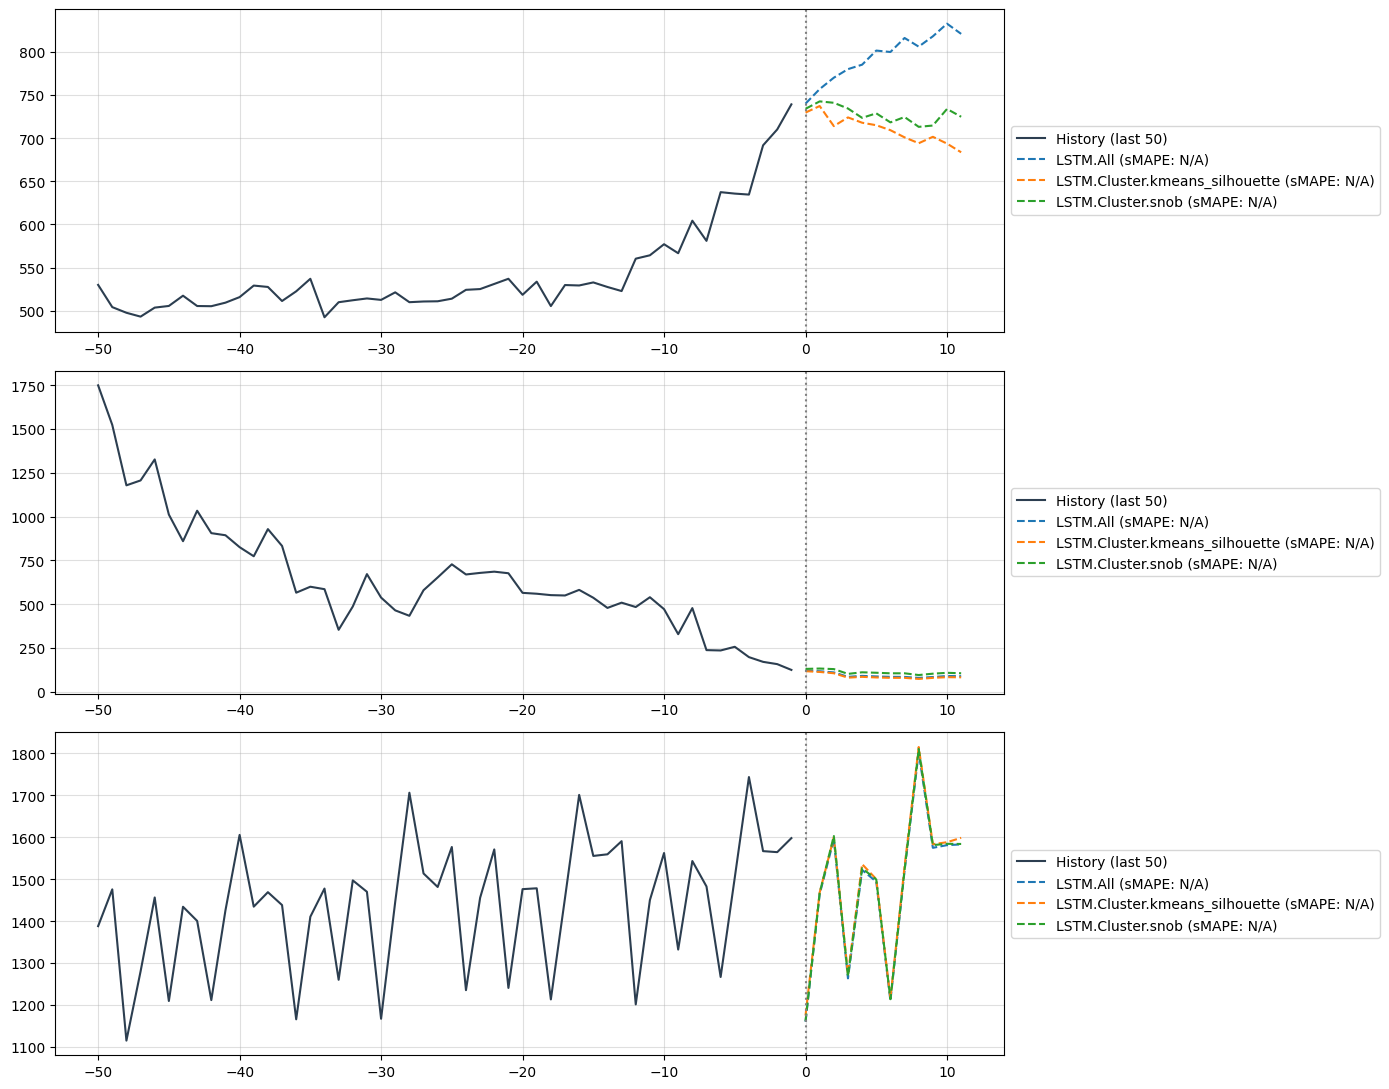

In [25]:
HP = dict(cell_dim=50, lr=5e-3, max_epochs=40, chunk=24, noise=0.002, l2=6e-4, patience=8, clip=1.0)
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
np.random.seed(0)

class PeepholeLSTM(nn.Module):
    def __init__(self, input_size, hidden):
        super().__init__()
        self.hidden = hidden
        self.ih = nn.Linear(input_size, 4 * hidden)
        self.hh = nn.Linear(hidden, 4 * hidden, bias=False)
        self.p_i = nn.Parameter(torch.zeros(hidden))
        self.p_f = nn.Parameter(torch.zeros(hidden))
        self.p_o = nn.Parameter(torch.zeros(hidden))
        with torch.no_grad():
            self.ih.bias[hidden:2 * hidden] = 1.0

    def forward(self, x, state=None):
        B, L, _ = x.shape
        if state is None:
            h = x.new_zeros(B, self.hidden); c = x.new_zeros(B, self.hidden)
        else:
            h, c = state
        gx = self.ih(x)
        outs = []
        for t in range(L):
            i, f, g, o = (gx[:, t] + self.hh(h)).chunk(4, -1)
            i = torch.sigmoid(i + self.p_i * c)
            f = torch.sigmoid(f + self.p_f * c)
            c = f * c + i * torch.tanh(g)
            o = torch.sigmoid(o + self.p_o * c)
            h = o * torch.tanh(c)
            outs.append(h)
        return torch.stack(outs, 1), (h, c)

class LSTMForecaster(nn.Module):
    def __init__(self, input_size, output_size, hidden):
        super().__init__()
        self.lstm = PeepholeLSTM(input_size, hidden)
        self.fc = nn.Linear(hidden, output_size, bias=False)

def stack_views_cif(views):
    T = max(v["X"].shape[0] for v in views)
    S, I, O = len(views), views[0]["X"].shape[1], views[0]["Y"].shape[1]

    X = np.zeros((S, T, I), dtype=np.float32)
    Y = np.zeros((S, T, O), dtype=np.float32)
    M = np.zeros((S, T), dtype=np.float32)
    final_idx = np.zeros(S, dtype=int)

    for k, v in enumerate(views):
        t = v["X"].shape[0]
        X[k, :t] = v["X"]
        Y[k, :t] = np.nan_to_num(v["Y"])
        M[k, :t] = v["mask"]
        final_idx[k] = v["final_idx"]

    return X, Y, M, final_idx

@torch.no_grad()
def last_row_forecast_cif(model, X, final_idx, chunk):
    model.eval()
    state = None
    all_outs = []

    for s in range(0, X.shape[1], chunk):
        o, state = model.lstm(X[:, s:s + chunk], state)
        all_outs.append(o)

    full_output = torch.cat(all_outs, dim=1)

    B = X.shape[0]
    preds = full_output[np.arange(B), final_idx]
    return model.fc(preds).cpu().numpy()

def fit_predict_cluster(val_views, test_views, hp=HP, device="cpu", tag=""):
    Xv_np, Yv_np, Mv_np, final_idx_v = stack_views_cif(val_views)
    Xt_np, _, _, final_idx_t = stack_views_cif(test_views)

    Xv = torch.tensor(Xv_np, device=device)
    Yv = torch.tensor(Yv_np, device=device)
    Mv = torch.tensor(Mv_np, device=device)
    Xt = torch.tensor(Xt_np, device=device)

    in_dim, out_dim = Xv.shape[2], Yv.shape[2]
    model = LSTMForecaster(in_dim, out_dim, hp["cell_dim"]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=hp["lr"], weight_decay=hp["l2"])

    best, best_state, bad = np.inf, None, 0
    T, ch = Xv.shape[1], hp["chunk"]

    for ep in range(hp["max_epochs"]):
        model.train()
        state = None
        for s in range(0, T, ch):
            mb = Mv[:, s:s + ch]
            if mb.sum() == 0:
                break
            xb = Xv[:, s:s + ch]
            xb = xb + hp["noise"] * torch.randn_like(xb)
            o, state = model.lstm(xb, state)
            state = (state[0].detach(), state[1].detach())

            err = ((model.fc(o) - Yv[:, s:s + ch]) ** 2).mean(-1)
            loss = (err * mb).sum() / mb.sum()
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), hp["clip"])
            opt.step()

        pv = last_row_forecast_cif(model, Xv, final_idx_v, ch)
        val_errors = [smape(v["target"], postprocess(p, v)) for p, v in zip(pv, val_views) if not np.isnan(v["target"]).all()]
        val = np.mean(val_errors) if val_errors else np.inf

        if val < best - 1e-4:
            best, bad = val, 0
            best_state = {k: x.clone() for k, x in model.state_dict().items()}
        else:
            bad += 1
            if bad >= hp["patience"]:
                break

    model.load_state_dict(best_state)
    pt = last_row_forecast_cif(model, Xt, final_idx_t, ch)
    print(f"  [{tag:<18}] {len(val_views):>3} series | best val sMAPE {best:>5.2f}% | epochs {ep + 1}")
    return [postprocess(p, v) for p, v in zip(pt, test_views)]

if __name__ == "__main__":
    FILE_PATH = "cif2016_data/cif2016_prepared.pkl"

    print(f"Loading prepared data from {FILE_PATH}...")
    with open(FILE_PATH, "rb") as f:
        cif_data = pickle.load(f)

    variants = cif_data["variants"]

    METHODS = ["LSTM.All", "LSTM.Cluster.kmeans_silhouette", "LSTM.Cluster.snob"]

    results = {}

    for method_name in METHODS:
        if method_name not in variants:
            continue

        print(f"\n========== Evaluating {method_name} ==========")
        groups = variants[method_name]
        results[method_name] = {}
        all_smapes = []

        for g in groups:
            val_views = [s["val_view"] for s in g["series"]]
            test_views = [s["test_view"] for s in g["series"]]

            preds = fit_predict_cluster(val_views, test_views, hp=HP, device=device, tag=g["name"])

            for i, s in enumerate(g["series"]):
                sid = s["id"]
                actual = s["test"]
                err = np.nan

                if actual is not None and not np.isnan(actual).all():
                    err = smape(actual, preds[i])
                    all_smapes.append(err)

                results[method_name][sid] = {
                    "forecast": preds[i],
                    "smape": err,
                    "history": s["y"],
                    "actual": actual,
                    "horizon": s["horizon"]
                }

        if all_smapes:
            print(f"--> {method_name}: mean sMAPE {np.mean(all_smapes):.2f}% | median sMAPE {np.median(all_smapes):.2f}%")
        else:
            print(f"--> {method_name}: Finished (No test targets available for final sMAPE)")

    print("\nPlotting results...")
    baseline = METHODS[0]
    all_series_ids = list(results[baseline].keys())

    rng = np.random.RandomState(42)
    sample_ids = rng.choice(all_series_ids, 3, replace=False)

    fig, axes = plt.subplots(3, 1, figsize=(14, 11))

    for ax, sid in zip(axes, sample_ids):
        hist = results[baseline][sid]["history"]
        actual = results[baseline][sid]["actual"]
        horizon = results[baseline][sid]["horizon"]

        plot_hist = hist[-50:]

        ax.plot(range(-len(plot_hist), 0), plot_hist, color="#2c3e50", label="History (last 50)")

        if actual is not None and not np.isnan(actual).all():
            ax.plot(range(horizon), actual, color="#27ae60", label="Actual Test Data")

        for m in METHODS:
            if m in results and sid in results[m]:
                r = results[m][sid]
                err_str = f"{r['smape']:.1f}%" if not np.isnan(r['smape']) else "N/A"
                ax.plot(range(horizon), r["forecast"], "--", label=f"{m} (sMAPE: {err_str})")

        ax.axvline(0, color="grey", ls=":")
        ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
        ax.grid(alpha=0.4)

    plt.tight_layout()
    plt.show()